epsilon_0 = 2.342648
Equilibrium = (0.7954, 0.0000, 1.1952)


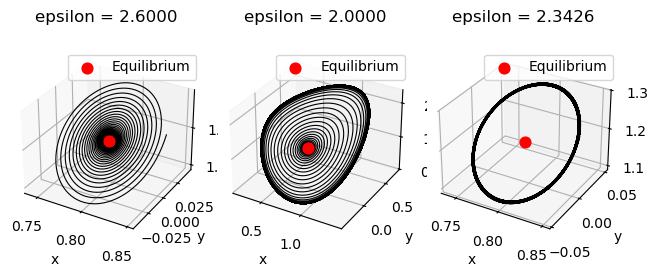

In [41]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

alpha = 2.0
beta = 0.7
eps0 = 2 * alpha * beta**1.5

x_star = np.arccos(beta)
y_star = 0.0
z_star = 1 / np.sqrt(beta)

print(f"epsilon_0 = {eps0:.6f}")
print(f"Equilibrium = ({x_star:.4f}, "
      f"{y_star:.4f}, {z_star:.4f})")

def sim(t, u, eps):
    x, y, z = u

    dx = y
    dy = np.sin(x) * (z**2 * np.cos(x) - 1) - eps * y
    dz = alpha * (np.cos(x) - beta)

    return [dx, dy, dz]

u0 = [
    x_star + 0.05,
    y_star + 0.02,
    z_star + 0.02
]

t_span = (0, 300)
t_eval = np.linspace(0, 300, 10000)

eps_values = [2.6, 2.0, 2.3426]

fig = plt.figure()

for i, eps in enumerate(eps_values):

    sol = solve_ivp(
        sim,
        t_span,
        u0,
        args=(eps,),
        t_eval=t_eval,
        method="RK45",
        rtol=1e-9,
        atol=1e-11
    )

    if not sol.success:
        print(sol.message)
        continue

    x, y, z = sol.y

    ax = fig.add_subplot(1, 3, i + 1, projection="3d")

    ax.plot(x, y, z, lw=0.8, color="black")

    ax.scatter(
        x_star, y_star, z_star,
        color="red", s=60, label="Equilibrium"
    )

    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_zlabel("z")

    ax.set_title(
        f"epsilon = {eps:.4f}\n"
    )

    ax.legend()

plt.tight_layout()
plt.show()


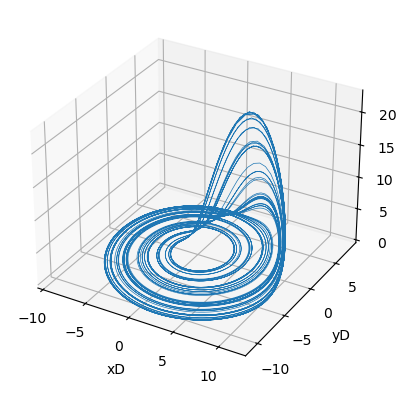

In [10]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

a=0.2
b=0.2
c=5.7

def driver(t, S):
    x, y, z = S
    return [-y-z, x+a*y, b+z*(x-c)]

t = np.linspace(0, 500, 10000)
solD = solve_ivp(
    driver, [0, 500], [0.5, 0.5, 0.5],
    t_eval=t, rtol=1e-9, atol=1e-11
)
xD, yD, zD = solD.y

mask = t >= 100

fig = plt.figure()
ax = fig.add_subplot(111, projection="3d")
ax.plot(xD[mask], yD[mask], zD[mask], lw=0.5)
ax.set_xlabel("xD")
ax.set_ylabel("yD")
ax.set_zlabel("zD")
plt.show()


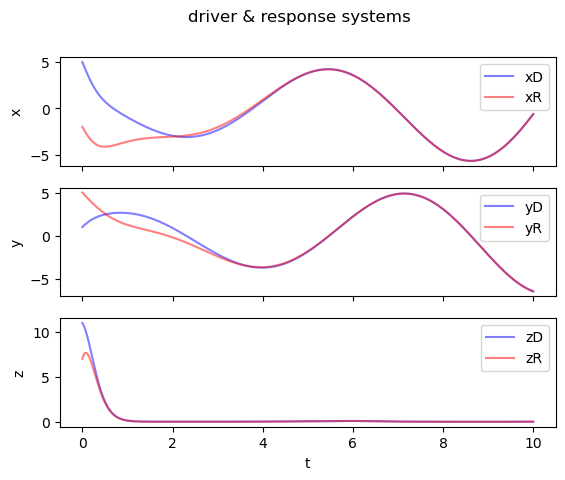

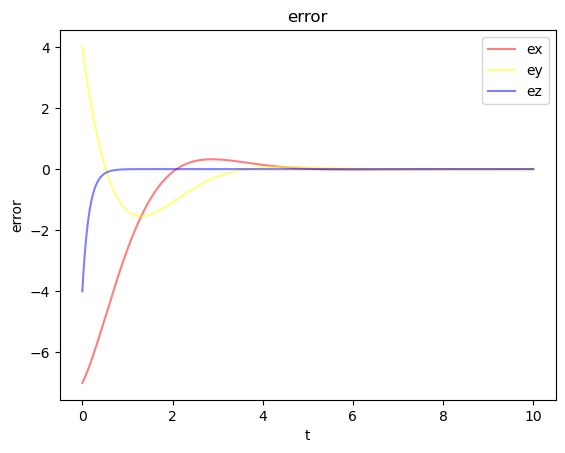

In [24]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

a=0.2
b=0.2
c=5.7
k1, k2, k3 = 1.0, 1.0, 1.0

def sim(t, S):
    xD, yD, zD = S[0:3]

    xR, yR, zR = S[3:6]

    ex = xR - xD
    ey = yR - yD
    ez = zR - zD

    u1 = -k1*ex + ez
    u2 = -(k2+a)*ey
    u3 = -k3*ez - zR*xR + zD*xD

    dxD = -yD - zD
    dyD = xD + a*yD
    dzD = b + zD*(xD-c)

    dxR = -yR - zR + u1
    dyR = xR + a*yR + u2
    dzR = b + zR*(xR-c) + u3

    return [dxD, dyD, dzD, dxR, dyR, dzR]


t = np.linspace(0, 10, 5000)

S0 = [5, 1, 11, -2, 5, 7]

sol = solve_ivp(
    sim,
    [0, 100],
    S0,
    t_eval=t,
    rtol=1e-9,
    atol=1e-11
)

xD, yD, zD = sol.y[0:3]
xR, yR, zR = sol.y[3:6]

ex = xR - xD
ey = yR - yD
ez = zR - zD

fig, axes = plt.subplots(3, 1,  sharex=True)

axes[0].plot(t, xD, color="blue", alpha=0.5,label="xD")
axes[0].plot(t, xR, color="red", alpha=0.5, label="xR")
axes[0].set_ylabel("x")
axes[0].legend()

axes[1].plot(t, yD,color="blue", alpha=0.5, label="yD")
axes[1].plot(t, yR, color="red", alpha=0.5, label="yR")
axes[1].set_ylabel("y")
axes[1].legend()

axes[2].plot(t, zD,color="blue", alpha=0.5, label="zD")
axes[2].plot(t, zR, color="red", alpha=0.5, label="zR")
axes[2].set_ylabel("z")
axes[2].set_xlabel("t")
axes[2].legend()

fig.suptitle("driver & response systems")
plt.show()

plt.figure()
plt.plot(t, ex, color="red", alpha=0.5, label="ex")
plt.plot(t, ey, color="yellow", alpha=0.5, label="ey")
plt.plot(t, ez, color="blue", alpha=0.5, label="ez")
plt.xlabel("t")
plt.ylabel("error")
plt.title("error")
plt.legend()
plt.show()
